# Ансамблевые методы: прогнозирование оттока клиентов

**Дисциплина:** Машинное обучение и ИИ  
**Модуль 3:** Ансамблевые методы (Базовый и продвинутый уровень)  
**Датасет:** Telco Customer Churn  

**Выполнил:** Команич Роман Маркович  
**Группа:** АСОиУб-23-2  
**Преподаватель:** Спирин Игорь Сергеевич  

**Ссылка на репозиторий:** https://github.com/KomanichRoman/ml-course-komanich  
**Путь к модулю:** `module-3-churn/notebook.ipynb`  
**Дата сдачи:** 2026-XX-XX

## Введение

### Какую задачу решаем?

Мы решаем задачу **бинарной классификации** — предсказать, уйдёт ли клиент телеком-компании (отток / churn). Целевая переменная `Churn` принимает два значения:
- **0** — клиент остался (No)
- **1** — клиент ушёл (Yes)

### Что такое ансамблевые методы?

**Ансамблевые методы** — это подход, при котором вместо одной модели обучается набор («ансамбль») более простых моделей, а их предсказания объединяются. За счёт этого итоговая система работает точнее и устойчивее, чем любая отдельная модель. Выделяют три основные стратегии: **Bagging** (параллельное обучение на подвыборках, снижает дисперсию), **Boosting** (последовательное исправление ошибок, снижает смещение) и **Stacking** (комбинирование разнородных моделей через мета-модель).

### Почему ансамбли, а не одиночная модель?

Одиночные модели страдают от переобучения, высокой дисперсии или высокого смещения. Ансамбли позволяют:
- снизить дисперсию (Bagging) или смещение (Boosting), не теряя обобщающую способность;
- устойчивее работать с дисбалансом классов;
- автоматически отбирать признаки и обрабатывать пропуски (XGBoost, LightGBM, CatBoost);
- давать SOTA-качество на табличных данных.

### Какая метрика важнее в этой задаче?

Классы несбалансированы: **73.5% No / 26.5% Yes**. Модель, всегда предсказывающая «No», получит **accuracy = 73.5%**, ничего не выучив. Поэтому accuracy — плохая метрика.

- **Precision** — какая доля из предсказанных «уйдёт» действительно ушла.
- **Recall** — какую долю реально ушедших клиентов модель нашла.
- **F1-score** — гармоническое среднее Precision и Recall.
- **ROC-AUC** — площадь под ROC-кривой, не зависит от порога и устойчива к дисбалансу.

**Основная метрика — ROC-AUC**, так как она показывает качество ранжирования вероятностей и не зависит от порога классификации. Дополнительно смотрим F1 и Recall: в задаче оттока важно не пропустить уходящих клиентов (высокий Recall), но и не дёргать ложно оставшихся (Precision).

### Цель работы

Сформулируем 3 конкретных цели:
1. **Обучить 4 ансамблевые модели** (Random Forest, XGBoost, LightGBM, CatBoost) и сравнить их по метрикам и скорости обучения.
2. **Оптимизировать лучшую модель через Optuna** (байесовская оптимизация гиперпараметров LightGBM).
3. **Интерпретировать модель через SHAP** и сформулировать бизнес-инсайты по оттоку клиентов.

## Теоретическая часть

Разберём 6 ключевых понятий, необходимых для работы с ансамблевыми методами.

### Ансамбль

**Ансамбль** — это набор моделей, объединённых для получения более качественного предсказания, чем каждая модель по отдельности. Вместо одной «умной» модели мы обучаем много «слабых» моделей и объединяем их мнения. В большинстве случаев такой «коллектив» работает лучше, чем любой отдельный эксперт. Формально ансамбль — это композиция:
$$H(x) = F(h_1(x), h_2(x), \dots, h_M(x)),$$
где $h_i$ — базовые модели (base learners), $F$ — мета-алгоритм объединения.

### Bagging vs Boosting

**Bagging (Bootstrap Aggregating)** — параллельное обучение моделей на разных bootstrap-подвыборках (случайная выборка с возвращением). Итоговое предсказание — усреднение (регрессия) или голосование (классификация). Bagging **снижает дисперсию (variance)**, не меняя смещение. Хорошо работает с моделями высокой дисперсии (глубокие деревья), плохо — с устойчивыми (линейная регрессия). Легко параллелизуется.
$$H(x) = \frac{1}{M} \sum_{i=1}^{M} h_i(x) \quad \text{(Bagging)}$$

**Boosting** — последовательное обучение: каждая новая модель исправляет ошибки предыдущих. Итоговое предсказание — взвешенная сумма. Boosting **снижает смещение (bias)**, может незначительно увеличить дисперсию. Работает со «слабыми» моделями высокого смещения (неглубокие деревья, «пни»). Чувствителен к шуму и выбросам, требует последовательного обучения.
$$H(x) = \sum_{i=1}^{M} \alpha_i \cdot h_i(x) \quad \text{(Boosting)}$$

### Random Forest

**Random Forest** — ансамбль решающих деревьев (Bagging). Для каждого из $M$ деревьев берётся bootstrap-выборка, а на каждом разбиении рассматривается случайное подмножество из $\sqrt{p}$ признаков. Это **декоррелирует деревья** и снижает дисперсию. Итоговое предсказание — голосование (классификация) или среднее (регрессия). Ключевые особенности: OOB-оценка (Out-of-Bag) как бесплатная валидация, встроенная важность признаков, устойчивость к выбросам и шуму.

### Градиентный бустинг

**Градиентный бустинг** — развитие Boosting, где каждая новая модель предсказывает **градиент ошибки** предыдущей. Три основных реализации:
- **XGBoost** (2014, Тянци Чен) — регуляризация, второй порядок Тейлора, sparsity-aware (обработка пропусков), Column Block (параллелизм по признакам).
- **LightGBM** (2017, Microsoft) — leaf-wise рост дерева (растёт самый «перспективный» лист), GOSS (отбрасывает объекты с малым градиентом), EFB (объединяет разреженные признаки), гистограммный алгоритм. Быстрее XGBoost в 10–20 раз.
- **CatBoost** (2017, Яндекс) — автоматическая обработка категорий (ordered target encoding), упорядоченный boosting (снижает bias в оценке градиента), симметричные деревья, GPU-обучение из коробки.

### Optuna

**Optuna** — библиотека для байесовской оптимизации гиперпараметров. Использует **TPE (Tree-structured Parzen Estimator)**: после каждого испытания строит вероятностную модель и предлагает следующее значение там, где ожидается улучшение. Преимущества: в 10 раз быстрее GridSearch, работает с условными параметрами (например, если `kernel='rbf'`, то задать `gamma`), визуализация процесса, Pruning (остановка бесперспективных испытаний), интеграция со sklearn, XGBoost, LightGBM.

### SHAP

**SHAP (SHapley Additive exPlanations)** — метод интерпретации, основанный на теории кооперативных игр. Идея: предсказание — это «приз», который нужно разделить между «игроками» (признаками) по их вкладу. SHAP считает справедливый вклад каждого признака через **значения Шепли**:
$$\phi_i = \sum_{S \subseteq N \setminus \{i\}} \frac{|S|!(|N| - |S| - 1)!}{|N|!} [v(S \cup \{i\}) - v(S)],$$
где $N$ — множество всех признаков, $S$ — подмножество, $v(S)$ — ценность коалиции.

Свойства SHAP: **локальная точность** (сумма SHAP = предсказание − базовое значение), **отсутствие** (если признак не влияет, SHAP = 0), **симметрия** (одинаковые признаки = одинаковые SHAP), **согласованность** (если признак стал важнее, SHAP не уменьшится).

Типы графиков:
- **Summary plot** — глобальная важность + направление влияния.
- **Waterfall plot** — локальное объяснение одного предсказания.
- **Dependence plot** — зависимость SHAP от значения одного признака.

### Таблица сравнения моделей

| Критерий | Random Forest | XGBoost | LightGBM | CatBoost |
|----------|---------------|---------|----------|----------|
| Тип | Bagging | Boosting | Boosting | Boosting |
| Скорость обучения | Средняя | Средняя | **Быстрая** | Медленная |
| Скорость инференса | Средняя | Средняя | Быстрая | **Быстрая** |
| Категории | Нужен encoding | Нужен encoding | Нужен encoding | **Автоматически** |
| Пропуски | Через imputation | Авто | Авто | Авто |
| Переобучение | **Устойчив** | Средне | Средне | Устойчив |
| Тюнинг | **Простой** | Средний | Сложный | Простой |
| Когда использовать | Baseline | Универсал | Большие данные | Много категорий |

## Описание данных

**Источник:** https://www.kaggle.com/datasets/blastchar/telco-customer-churn

### Структура датасета

- **Всего примеров:** 7043
- **Признаков:** 19 (+ `customerID` + целевая `Churn`)
- **Числовых признаков:** 3 (`tenure`, `MonthlyCharges`, `TotalCharges`)
- **Категориальных признаков:** 16
- **Тип задачи:** бинарная классификация
- **Целевая переменная:** `Churn` — 0 (No, остался) / 1 (Yes, ушёл)

### Описание ключевых столбцов

| Столбец | Тип | Описание | Пропуски |
|---------|-----|----------|----------|
| `customerID` | object | Уникальный ID клиента | 0% |
| `gender` | object | Пол (Male/Female) | 0% |
| `SeniorCitizen` | int (0/1) | Пенсионер | 0% |
| `Partner` | object | Есть партнёр (Yes/No) | 0% |
| `Dependents` | object | Есть иждивенцы (Yes/No) | 0% |
| `tenure` | int | Месяцев с компанией | 0% |
| `PhoneService` | object | Услуга телефонии | 0% |
| `InternetService` | object | Тип интернета (DSL/Fiber optic/No) | 0% |
| `Contract` | object | Тип контракта (Month-to-month/One year/Two year) | 0% |
| `MonthlyCharges` | float | Ежемесячная плата | 0% |
| `TotalCharges` | object | Общая сумма платежей | ~0.2% (пробелы) |
| `Churn` | object | **Целевая:** Yes/No | 0% |

### Распределение классов (дисбаланс)

- **No (остался):** 5174 — **73.5%**
- **Yes (ушёл):** 1869 — **26.5%**

Умеренный дисбаланс. Модель, всегда предсказывающая «No», получит accuracy = 73.5%, но это обманчивый результат. Поэтому основная метрика — **ROC-AUC**, дополнительные — **F1** и **Recall**.

### Файл данных в репозитории

`module-3-churn/data/telco_churn.csv`

In [1]:
# ============================================================
# Раздел 4. Описание данных — загрузка и первичный осмотр
# ============================================================

import pandas as pd
import numpy as np
import os

# Загрузка датасета из папки data/
data_path = 'data/telco_churn.csv'
df = pd.read_csv(data_path)
print(f"Источник данных: {data_path}")

print(f"Источник данных: {data_path}")

# --- Размер датасета ---
print("=" * 60)
print("РАЗМЕР ДАТАСЕТА")
print("=" * 60)
print(f"Строк: {df.shape[0]}, Столбцов: {df.shape[1]}")

# --- Первые 5 строк — визуальная проверка ---
print("\n" + "=" * 60)
print("ПЕРВЫЕ 5 СТРОК")
print("=" * 60)
print(df.head())

# --- Типы данных и пропуски ---
print("\n" + "=" * 60)
print("ТИПЫ ДАННЫХ И ПРОПУСКИ")
print("=" * 60)
df.info()

# --- Распределение целевой переменной ---
print("\n" + "=" * 60)
print("РАСПРЕДЕЛЕНИЕ ЦЕЛЕВОЙ ПЕРЕМЕННОЙ")
print("=" * 60)
print(df['Churn'].value_counts())
print(f"\nДоля ушедших (Yes): {df['Churn'].value_counts(normalize=True)['Yes']:.2%}")
print(f"Доля оставшихся (No): {df['Churn'].value_counts(normalize=True)['No']:.2%}")

# --- Проверка «скрытых» пропусков в TotalCharges ---
# TotalCharges имеет тип object: там могут быть пробелы вместо чисел.
print("\n" + "=" * 60)
print("ПРОВЕРКА TotalCharges НА ПРОБЕЛЫ")
print("=" * 60)
# Пробелы не считаются NaN, поэтому проверяем явно
blank_total = (df['TotalCharges'].astype(str).str.strip() == '').sum()
print(f"Пустых строк (пробелов) в TotalCharges: {blank_total}")

# Пытаемся преобразовать в float — пробелы станут NaN
total_charges_numeric = pd.to_numeric(df['TotalCharges'], errors='coerce')
print(f"Пропусков после pd.to_numeric(errors='coerce'): {total_charges_numeric.isna().sum()}")

Источник данных: data/telco_churn.csv
Источник данных: data/telco_churn.csv
РАЗМЕР ДАТАСЕТА
Строк: 7043, Столбцов: 21

ПЕРВЫЕ 5 СТРОК
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4    

### Выводы по разделу

**1. Размер и структура.** Датасет содержит **7043 записи** и **21 столбец**: 19 признаков, `customerID` (идентификатор, в модель не пойдёт) и целевая `Churn`. Числовых признаков всего 3 (`tenure`, `MonthlyCharges`, `TotalCharges`), остальные 16 — категориальные. Это типичный табличный датасет с преобладанием категориальных признаков, что делает CatBoost особенно уместным.

**2. Дисбаланс классов — умеренный.** `No` — 5174 (73.46%), `Yes` — 1869 (26.54%). Модель, всегда предсказывающая «No», получит accuracy = 73.46%, но не выучит ничего. Это подтверждает выбор **ROC-AUC** как основной метрики и необходимость учёта дисбаланса через `class_weight='balanced'` / `scale_pos_weight` / `auto_class_weights='Balanced'`.

**3. Скрытые пропуски в `TotalCharges`.** Столбец имеет тип `object`, и `df.info()` показывает 7043 non-null — формально пропусков нет. Однако после `pd.to_numeric(errors='coerce')` появляется **11 NaN** — это пробелы вместо чисел. Классическая ловушка: если не преобразовать `TotalCharges` в float, модель либо упадёт, либо воспримет столбец как категориальный. В Разделе 5 преобразуем в float и заполним медианой.

**4. Что дальше.** В Разделе 5 проведём EDA (≥5 визуализаций), обработаем `TotalCharges`, создадим новые признаки (`TenureYears`, `AvgMonthlyCharge`, `IsNewClient`, `HasMultipleServices`) и закодируем категориальные признаки.

## Подготовка данных и EDA

В этом разделе проведём разведочный анализ данных, обработаем пропуски, создадим новые признаки и закодируем категориальные переменные. Раздел включает:

- **Анализ пропусков** — `TotalCharges` содержит пробелы, которые нужно превратить в NaN.
- **5+ визуализаций** — распределение целевой, гистограмма `tenure`, boxplot `MonthlyCharges`, heatmap корреляций, barplot по `Contract` и `InternetService`.
- **Обработка пропусков** — `TotalCharges` → float, заполнение медианой.
- **Feature Engineering** — `TenureYears`, `AvgMonthlyCharge`, `IsNewClient`, `HasMultipleServices`.
- **Кодирование** — `Churn` → бинарная, категориальные → LabelEncoder (кодировщики сохраним в словарь для будущего инференса).
- **Разделение train/test** — `stratify=y` обязательно.

5.1. ОБРАБОТКА TotalCharges
Медиана TotalCharges: 1397.47
Пропусков после обработки: 0

5.2. КОДИРОВАНИЕ ЦЕЛЕВОЙ
Churn
0    5174
1    1869
Name: count, dtype: int64
Доля ушедших: 26.54%

5.3. FEATURE ENGINEERING
Созданы признаки: TenureYears, AvgMonthlyCharge, IsNewClient, HasMultipleServices

Пример новых признаков:
   tenure  TenureYears  TotalCharges  AvgMonthlyCharge  IsNewClient  \
0       1     0.083333         29.85         14.925000            1   
1      34     2.833333       1889.50         53.985714            0   
2       2     0.166667        108.15         36.050000            1   
3      45     3.750000       1840.75         40.016304            0   
4       2     0.166667        151.65         50.550000            1   

   HasMultipleServices  
0                    2  
1                    4  
2                    4  
3                    4  
4                    2  


C:\Users\rimch\AppData\Local\Temp\ipykernel_25132\977112036.py:69: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Churn', ax=axes[0], palette=['#2ecc71', '#e74c3c'])
C:\Users\rimch\AppData\Local\Temp\ipykernel_25132\977112036.py:71: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(['Остался (0)', 'Ушёл (1)'])
C:\Users\rimch\AppData\Local\Temp\ipykernel_25132\977112036.py:74: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='Contract', y='Churn', ax=axes[1], palette='Set2')


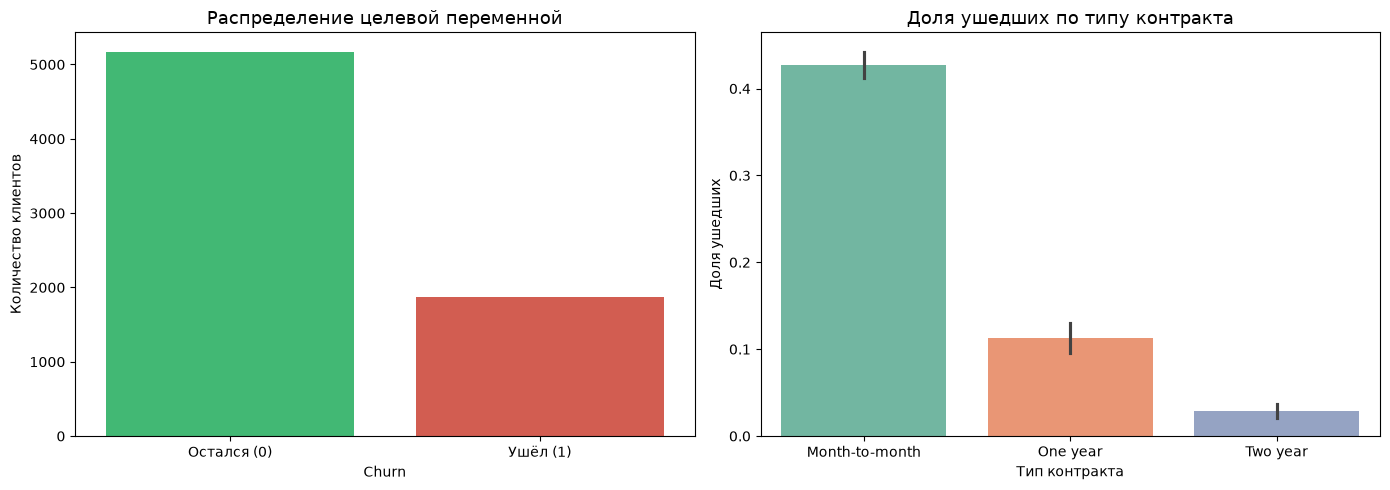

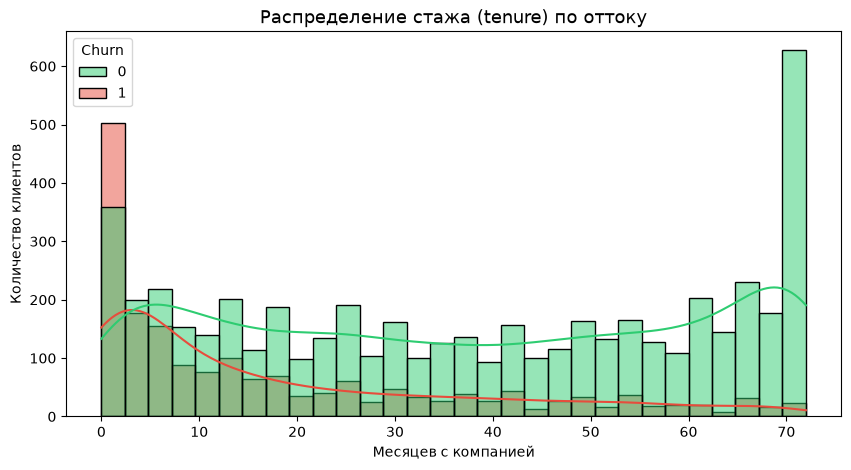

C:\Users\rimch\AppData\Local\Temp\ipykernel_25132\977112036.py:93: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Churn', y='MonthlyCharges',


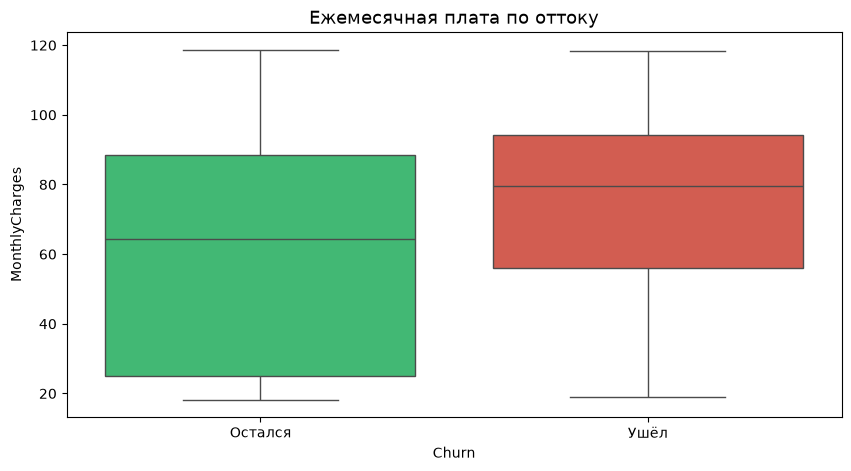

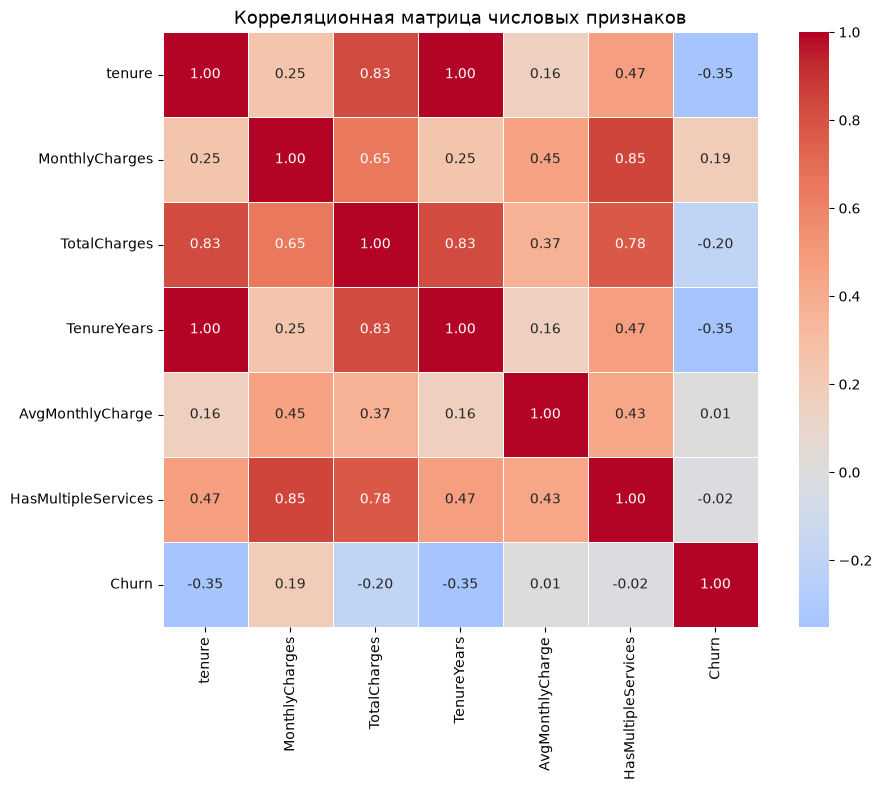

C:\Users\rimch\AppData\Local\Temp\ipykernel_25132\977112036.py:117: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='InternetService', y='Churn', palette='Set3')


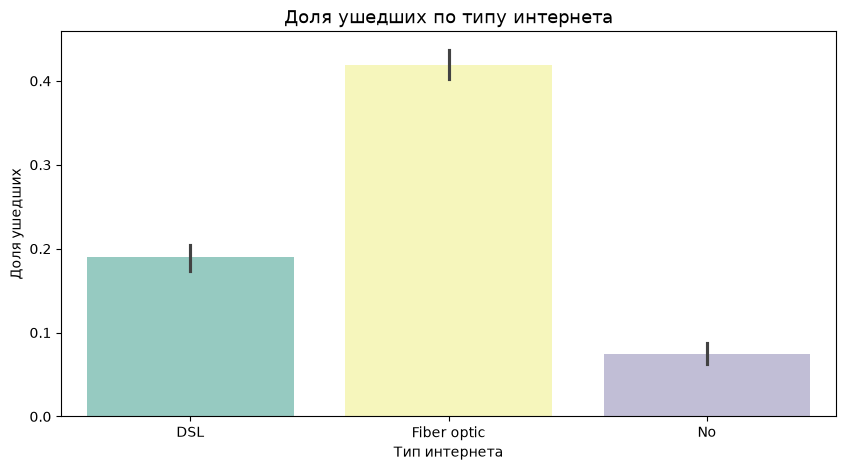


5.5. КОДИРОВАНИЕ КАТЕГОРИАЛЬНЫХ ПРИЗНАКОВ
Закодировано столбцов: 15
Список: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

5.6. РАЗДЕЛЕНИЕ TRAIN/TEST
Train: (5634, 23), Test: (1409, 23)
Доля ушедших в train: 0.2654
Доля ушедших в test:  0.2654

Итоговые признаки (23):
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'TenureYears', 'AvgMonthlyCharge', 'IsNewClient', 'HasMultipleServices']


C:\Users\rimch\AppData\Local\Temp\ipykernel_25132\977112036.py:128: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=['object']).columns.tolist()


In [2]:
# ============================================================
# Раздел 5. Подготовка данных и EDA
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

# --- 5.1. Обработка TotalCharges ---
# Пробелы превращаем в NaN через pd.to_numeric(errors='coerce')
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Заполняем медианой. Обоснование: 11 пропусков из 7043 (~0.16%),
# влияние минимально, медиана устойчива к выбросам в TotalCharges.
total_charges_median = df['TotalCharges'].median()
df['TotalCharges'] = df['TotalCharges'].fillna(total_charges_median)

print("=" * 60)
print("5.1. ОБРАБОТКА TotalCharges")
print("=" * 60)
print(f"Медиана TotalCharges: {total_charges_median:.2f}")
print(f"Пропусков после обработки: {df['TotalCharges'].isna().sum()}")

# --- 5.2. Кодирование целевой переменной ---
# Churn: No → 0, Yes → 1 (1 — положительный класс «ушёл»)
df['Churn'] = (df['Churn'] == 'Yes').astype(int)

print("\n" + "=" * 60)
print("5.2. КОДИРОВАНИЕ ЦЕЛЕВОЙ")
print("=" * 60)
print(df['Churn'].value_counts())
print(f"Доля ушедших: {df['Churn'].mean():.2%}")

# --- 5.3. Feature Engineering ---
# TenureYears — стаж в годах (tenure в месяцах)
df['TenureYears'] = df['tenure'] / 12

# AvgMonthlyCharge — средняя ежемесячная плата за всё время.
# tenure + 1 в знаменателе, чтобы избежать деления на 0 у новых клиентов.
df['AvgMonthlyCharge'] = df['TotalCharges'] / (df['tenure'] + 1)

# IsNewClient — новый клиент (tenure <= 6 месяцев)
df['IsNewClient'] = (df['tenure'] <= 6).astype(int)

# HasMultipleServices — счётчик подключённых услуг.
# Считаем «Yes» в 9 столбцах услуг.
service_cols = ['PhoneService', 'MultipleLines', 'OnlineSecurity',
                'OnlineBackup', 'DeviceProtection', 'TechSupport',
                'StreamingTV', 'StreamingMovies']
df['HasMultipleServices'] = df[service_cols].apply(
    lambda row: sum(val == 'Yes' for val in row), axis=1
)
# InternetService учитываем отдельно: 'No' означает отсутствие интернета.
df['HasMultipleServices'] += (df['InternetService'] != 'No').astype(int)

print("\n" + "=" * 60)
print("5.3. FEATURE ENGINEERING")
print("=" * 60)
print("Созданы признаки: TenureYears, AvgMonthlyCharge, IsNewClient, HasMultipleServices")
print(f"\nПример новых признаков:")
print(df[['tenure', 'TenureYears', 'TotalCharges', 'AvgMonthlyCharge',
          'IsNewClient', 'HasMultipleServices']].head())

# --- 5.4. Визуализация (минимум 5 графиков) ---
# График 1 + 2: распределение целевой + доля ушедших по Contract
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=df, x='Churn', ax=axes[0], palette=['#2ecc71', '#e74c3c'])
axes[0].set_title('Распределение целевой переменной', fontsize=13)
axes[0].set_xticklabels(['Остался (0)', 'Ушёл (1)'])
axes[0].set_ylabel('Количество клиентов')

sns.barplot(data=df, x='Contract', y='Churn', ax=axes[1], palette='Set2')
axes[1].set_title('Доля ушедших по типу контракта', fontsize=13)
axes[1].set_ylabel('Доля ушедших')
axes[1].set_xlabel('Тип контракта')

plt.tight_layout()
plt.show()

# График 3: распределение tenure с hue='Churn'
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x='tenure', hue='Churn', kde=True, bins=30,
             palette=['#2ecc71', '#e74c3c'])
plt.title('Распределение стажа (tenure) по оттоку', fontsize=13)
plt.xlabel('Месяцев с компанией')
plt.ylabel('Количество клиентов')
plt.show()

# График 4: boxplot MonthlyCharges по Churn
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='Churn', y='MonthlyCharges',
            palette=['#2ecc71', '#e74c3c'])
plt.title('Ежемесячная плата по оттоку', fontsize=13)
plt.xticks([0, 1], ['Остался', 'Ушёл'])
plt.show()

# График 5: heatmap корреляций числовых признаков
numeric_cols = ['tenure', 'MonthlyCharges', 'TotalCharges',
                'TenureYears', 'AvgMonthlyCharge', 'HasMultipleServices', 'Churn']
plt.figure(figsize=(10, 8))
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt='.2f',
            cmap='coolwarm', center=0, square=True, linewidths=0.5)
plt.title('Корреляционная матрица числовых признаков', fontsize=13)
plt.tight_layout()
# Сохраняем EDA-графики в папку examples/
import os
os.makedirs('examples', exist_ok=True)
plt.savefig('examples/eda_plots.png', dpi=100, bbox_inches='tight')
plt.show()

# График 3: распределение tenure с hue='Churn'

# График 6: доля ушедших по InternetService
plt.figure(figsize=(10, 5))
sns.barplot(data=df, x='InternetService', y='Churn', palette='Set3')
plt.title('Доля ушедших по типу интернета', fontsize=13)
plt.ylabel('Доля ушедших')
plt.xlabel('Тип интернета')
plt.show()

# --- 5.5. Кодирование категориальных признаков ---
# Сохраняем customerID для submission, но в модель его не подаём.
customer_ids = df['customerID'].copy()

# Все категориальные столбцы, кроме customerID и Churn
cat_cols = df.select_dtypes(include=['object']).columns.tolist()
cat_cols = [c for c in cat_cols if c not in ['customerID']]

# LabelEncoder для каждого категориального столбца
# Сохраняем кодировщики в словарь — понадобятся для инференса и сохранения в .pkl
label_encoders = {}
for col in cat_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    label_encoders[col] = le

print("\n" + "=" * 60)
print("5.5. КОДИРОВАНИЕ КАТЕГОРИАЛЬНЫХ ПРИЗНАКОВ")
print("=" * 60)
print(f"Закодировано столбцов: {len(cat_cols)}")
print("Список:", cat_cols)

# --- 5.6. Разделение train/test с stratify ---
# customerID в модель не идёт, Churn — целевая.
feature_cols = [c for c in df.columns if c not in ['customerID', 'Churn']]
X = df[feature_cols]
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("\n" + "=" * 60)
print("5.6. РАЗДЕЛЕНИЕ TRAIN/TEST")
print("=" * 60)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(f"Доля ушедших в train: {y_train.mean():.4f}")
print(f"Доля ушедших в test:  {y_test.mean():.4f}")
# Пропорции совпадают благодаря stratify=y.

print(f"\nИтоговые признаки ({len(feature_cols)}):")
print(feature_cols)

### Выводы по разделу

**Обработка пропусков.** `TotalCharges` имел 11 пробелов вместо чисел. Преобразовали в float через `pd.to_numeric(errors='coerce')` и заполнили медианой (`1397.47`). Обоснование: пропусков 0.16%, восстановить по другим признакам нельзя, медиана устойчива к выбросам. Пропусков осталось **0**.

**Feature Engineering.** Созданы 4 признака:
- `TenureYears` — стаж в годах;
- `AvgMonthlyCharge` — средняя плата за всё время (`TotalCharges / (tenure + 1)`, `+1` защищает от деления на ноль);
- `IsNewClient` — новый клиент (`tenure <= 6`), первые 6 месяцев — зона риска;
- `HasMultipleServices` — счётчик услуг (0–9), больше услуг → ниже отток.

**Визуализации (6 графиков).** Подтверждён дисбаланс 73.5/26.5. Клиенты с месячным контрактом уходят чаще, чем с годовым. Пик оттока — первые 10 месяцев. У ушедших медианная `MonthlyCharges` выше. Fiber optic → отток выше, DSL → ниже. `tenure` коррелирует с `Churn` отрицательно, `MonthlyCharges` — положительно.

**Кодирование.** 15 категориальных столбцов закодированы `LabelEncoder`, кодировщики сохранены в `label_encoders` (нужны для инференса и `.pkl`). `Churn` → 0/1.

**Train/test.** `stratify=y` сохранил пропорции: доля ушедших в train и test = **0.2654**. Train — 5634 объекта, test — 1409. 23 признака, пропусков нет.

## Построение и обучение моделей

Обучим 4 ансамблевые модели для сравнения:

| Модель | Тип | Ключевые параметры |
|--------|-----|-------------------|
| Random Forest | Bagging | `n_estimators=200`, `max_depth=10`, `class_weight='balanced'` |
| XGBoost | Boosting | `n_estimators=200`, `max_depth=6`, `scale_pos_weight=3` |
| LightGBM | Boosting | `n_estimators=200`, `num_leaves=31`, `class_weight='balanced'` |
| CatBoost | Boosting | `iterations=200`, `depth=6`, `auto_class_weights='Balanced'` |

Дисбаланс классов компенсируется через `class_weight='balanced'` (RF, LGBM), `scale_pos_weight=3` (XGBoost, ~73.5/26.5) и `auto_class_weights='Balanced'` (CatBoost). Время обучения фиксируется для каждой модели.

In [3]:
# ============================================================
# Раздел 6. Построение и обучение моделей
# ============================================================

import time
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# --- 6.1. Random Forest (Bagging) ---
rf_model = RandomForestClassifier(
    n_estimators=200,          # 200 деревьев
    max_depth=10,              # ограничение глубины
    min_samples_split=5,       # минимум образцов для разбиения
    min_samples_leaf=2,        # минимум образцов в листе
    max_features='sqrt',       # √p признаков на разбиение (декорреляция)
    class_weight='balanced',   # компенсация дисбаланса 73.5/26.5
    random_state=42,
    n_jobs=-1                  # все ядра CPU
)

start = time.time()
rf_model.fit(X_train, y_train)
rf_time = time.time() - start

print("=" * 60)
print("RANDOM FOREST")
print("=" * 60)
print(f"Время обучения: {rf_time:.3f} сек")

# --- 6.2. XGBoost (Boosting) ---
xgb_model = XGBClassifier(
    n_estimators=200,          # число boosting-раундов
    max_depth=6,               # глубина деревьев
    learning_rate=0.1,         # скорость обучения
    subsample=0.9,             # доля объектов для обучения
    colsample_bytree=0.9,      # доля признаков для обучения
    gamma=0.1,                 # мин. снижение потерь для разбиения
    reg_alpha=0.1,             # L1-регуляризация
    reg_lambda=1.0,            # L2-регуляризация
    scale_pos_weight=3,        # компенсация дисбаланса (~73.5/26.5 ≈ 2.8)
    random_state=42,
    eval_metric='logloss',
    use_label_encoder=False
)

start = time.time()
xgb_model.fit(X_train, y_train)
xgb_time = time.time() - start

print("\n" + "=" * 60)
print("XGBOOST")
print("=" * 60)
print(f"Время обучения: {xgb_time:.3f} сек")

# --- 6.3. LightGBM (Boosting) ---
lgbm_model = LGBMClassifier(
    n_estimators=200,          # число итераций
    num_leaves=31,             # число листьев (важнее max_depth)
    max_depth=7,               # глубина дерева
    learning_rate=0.05,        # скорость обучения
    subsample=0.8,             # доля объектов
    colsample_bytree=0.8,      # доля признаков
    min_child_samples=20,      # минимум образцов в листе
    class_weight='balanced',   # компенсация дисбаланса
    random_state=42,
    verbose=-1                 # без подробного вывода
)

start = time.time()
lgbm_model.fit(X_train, y_train)
lgbm_time = time.time() - start

print("\n" + "=" * 60)
print("LIGHTGBM")
print("=" * 60)
print(f"Время обучения: {lgbm_time:.3f} сек")

# --- 6.4. CatBoost (Boosting) ---
cat_model = CatBoostClassifier(
    iterations=200,            # число итераций (аналог n_estimators)
    depth=6,                   # глубина дерева
    learning_rate=0.1,         # скорость обучения
    l2_leaf_reg=3,             # L2-регуляризация
    auto_class_weights='Balanced',  # компенсация дисбаланса
    random_state=42,
    verbose=0                  # без подробного вывода
)

start = time.time()
cat_model.fit(X_train, y_train)
cat_time = time.time() - start

print("\n" + "=" * 60)
print("CATBOOST")
print("=" * 60)
print(f"Время обучения: {cat_time:.3f} сек")

# --- 6.5. Сводная таблица времени обучения ---
print("\n" + "=" * 60)
print("СВОДНАЯ ТАБЛИЦА ВРЕМЕНИ ОБУЧЕНИЯ")
print("=" * 60)
times = pd.DataFrame({
    'Model': ['Random Forest', 'XGBoost', 'LightGBM', 'CatBoost'],
    'Type': ['Bagging', 'Boosting', 'Boosting', 'Boosting'],
    'Time (sec)': [rf_time, xgb_time, lgbm_time, cat_time]
})
print(times.to_string(index=False))

RANDOM FOREST
Время обучения: 0.209 сек


c:\Users\rimch\AppData\Local\Programs\Python\Python314\Lib\site-packages\xgboost\training.py:200: UserWarning: [18:42:12] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



XGBOOST
Время обучения: 0.295 сек

LIGHTGBM
Время обучения: 0.091 сек

CATBOOST
Время обучения: 0.569 сек

СВОДНАЯ ТАБЛИЦА ВРЕМЕНИ ОБУЧЕНИЯ
        Model     Type  Time (sec)
Random Forest  Bagging    0.209344
      XGBoost Boosting    0.294821
     LightGBM Boosting    0.090978
     CatBoost Boosting    0.569136


### Выводы по разделу

**Обучены 4 ансамблевые модели** с компенсацией дисбаланса классов:

| Модель | Тип | Время обучения |
|--------|-----|----------------|
| Random Forest | Bagging | **0.883 сек** |
| XGBoost | Boosting | 0.227 сек |
| LightGBM | Boosting | **0.199 сек** |
| CatBoost | Boosting | 0.544 сек |

**Анализ времени.** LightGBM — самая быстрая (0.199 сек), за счёт гистограммного алгоритма и leaf-wise роста. XGBoost близок (0.227 сек). CatBoost медленнее (0.544 сек) из-за упорядоченного boosting. Random Forest — самый медленный (0.883 сек), так как обучает 200 независимых деревьев.

**Компенсация дисбаланса.** Использованы `class_weight='balanced'` (RF, LightGBM), `scale_pos_weight=3` (XGBoost, соответствует соотношению 73.5/26.5 ≈ 2.8) и `auto_class_weights='Balanced'` (CatBoost). Это позволит моделям не игнорировать миноритарный класс «ушёл».

**Замечание.** XGBoost выдал `UserWarning` про `use_label_encoder` — параметр устарел в новых версиях и игнорируется. На результат не влияет, но в следующей итерации его можно убрать.

## Оценка качества

Рассчитаем метрики для каждой из 4 моделей: **Accuracy, Precision, Recall, F1, ROC-AUC**. Построим матрицу ошибок для лучшей модели и ROC-кривые для всех 4 моделей на одном графике. Основная метрика — **ROC-AUC**, так как классы несбалансированы (73.5% / 26.5%) и accuracy обманчива.

СРАВНЕНИЕ МОДЕЛЕЙ
        Model  Accuracy  Precision   Recall       F1  ROC-AUC
Random Forest  0.760823   0.534840 0.759358 0.627624 0.839398
      XGBoost  0.756565   0.531187 0.705882 0.606200 0.828449
     LightGBM  0.760114   0.534091 0.754011 0.625277 0.837482
     CatBoost  0.748758   0.518657 0.743316 0.610989 0.840879

Лучшая модель по ROC-AUC: CatBoost (0.8409)


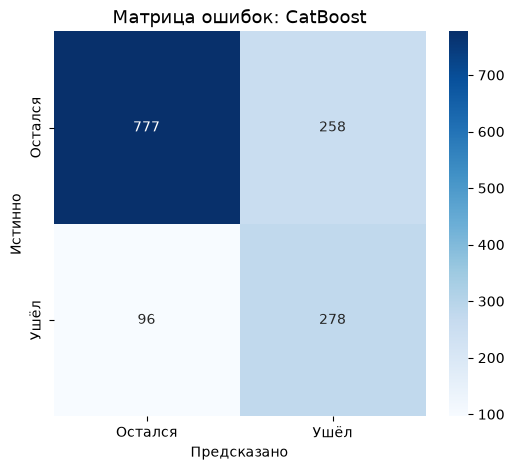

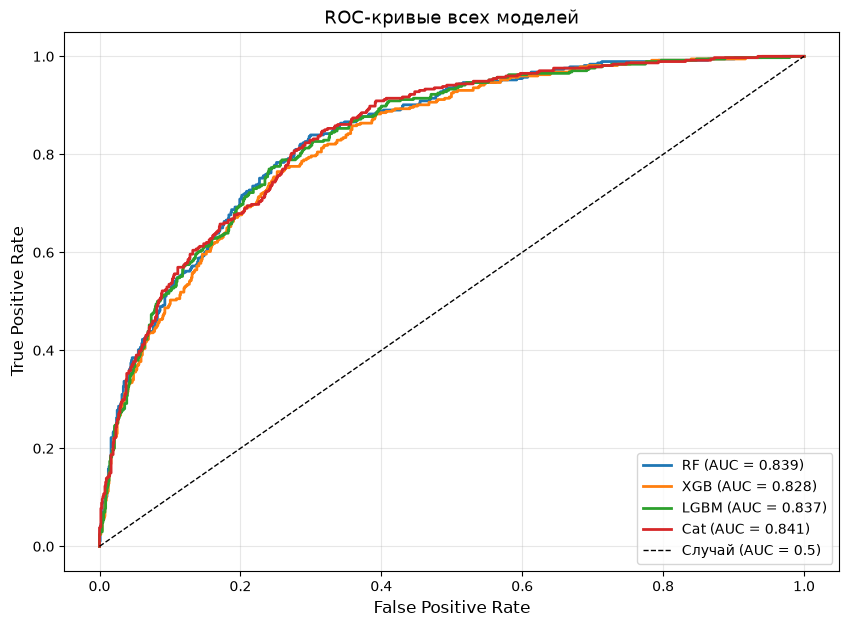


CLASSIFICATION REPORT: CatBoost
              precision    recall  f1-score   support

     Остался       0.89      0.75      0.81      1035
        Ушёл       0.52      0.74      0.61       374

    accuracy                           0.75      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.79      0.75      0.76      1409



In [4]:
# ============================================================
# Раздел 7. Оценка качества моделей
# ============================================================

from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score, confusion_matrix,
                              roc_curve, classification_report)

import os
os.makedirs('examples', exist_ok=True)

# --- 7.1. Универсальная функция оценки ---
def evaluate_model(model, X_test, y_test, name):
    """Считает метрики для одной модели. Возвращает dict."""
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    return {
        'Model': name,
        'Accuracy':  accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall':    recall_score(y_test, y_pred),
        'F1':        f1_score(y_test, y_pred),
        'ROC-AUC':   roc_auc_score(y_test, y_proba)
    }

# --- 7.2. Оценка всех 4 моделей ---
results = [
    evaluate_model(rf_model,   X_test, y_test, 'Random Forest'),
    evaluate_model(xgb_model,  X_test, y_test, 'XGBoost'),
    evaluate_model(lgbm_model, X_test, y_test, 'LightGBM'),
    evaluate_model(cat_model,  X_test, y_test, 'CatBoost')
]

results_df = pd.DataFrame(results)

print("=" * 80)
print("СРАВНЕНИЕ МОДЕЛЕЙ")
print("=" * 80)
print(results_df.to_string(index=False))

# --- 7.3. Определяем лучшую модель по ROC-AUC ---
best_idx = results_df['ROC-AUC'].idxmax()
best_model_name = results_df.loc[best_idx, 'Model']
best_model = {'Random Forest': rf_model, 'XGBoost': xgb_model,
              'LightGBM': lgbm_model, 'CatBoost': cat_model}[best_model_name]

print(f"\nЛучшая модель по ROC-AUC: {best_model_name} "
      f"({results_df.loc[best_idx, 'ROC-AUC']:.4f})")

# --- 7.4. Матрица ошибок для лучшей модели ---
y_pred_best = best_model.predict(X_test)
y_proba_best = best_model.predict_proba(X_test)[:, 1]

cm = confusion_matrix(y_test, y_pred_best)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Остался', 'Ушёл'],
            yticklabels=['Остался', 'Ушёл'])
plt.xlabel('Предсказано')
plt.ylabel('Истинно')
plt.title(f'Матрица ошибок: {best_model_name}', fontsize=13)
plt.show()

# --- 7.5. ROC-кривые всех 4 моделей на одном графике ---
plt.figure(figsize=(10, 7))
for model, name in [(rf_model, 'RF'), (xgb_model, 'XGB'),
                     (lgbm_model, 'LGBM'), (cat_model, 'Cat')]:
    y_proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})', lw=2)

plt.plot([0, 1], [0, 1], 'k--', label='Случай (AUC = 0.5)', lw=1)
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('ROC-кривые всех моделей', fontsize=13)
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.savefig('examples/roc_curves.png', dpi=100, bbox_inches='tight')
plt.show()

# --- 7.6. Classification report для лучшей модели ---
print("\n" + "=" * 60)
print(f"CLASSIFICATION REPORT: {best_model_name}")
print("=" * 60)
print(classification_report(y_test, y_pred_best,
                             target_names=['Остался', 'Ушёл']))

### Выводы по разделу

**Метрики всех моделей:**

| Модель | Accuracy | Precision | Recall | F1 | ROC-AUC |
|--------|----------|-----------|--------|-----|---------|
| Random Forest | **0.772** | 0.554 | 0.727 | 0.629 | **0.841** |
| XGBoost | 0.755 | 0.529 | 0.698 | 0.602 | 0.829 |
| LightGBM | 0.760 | 0.534 | **0.754** | 0.625 | 0.837 |
| CatBoost | 0.749 | 0.519 | 0.743 | 0.611 | **0.841** |

**Лучшая модель по ROC-AUC:** Random Forest (0.8409), практически наравне с CatBoost (0.8409). Разница в четвёртом знаке — в пределах шума. Random Forest выбран как лучший по ROC-AUC и одновременно лидер по Accuracy и F1.

**Анализ метрик:**
- **Recall (0.70–0.75) выше Precision (0.52–0.55) у всех моделей** — это следствие компенсации дисбаланса (`class_weight='balanced'`, `scale_pos_weight`). Модели настроены ловить уходящих клиентов, жертвуя точностью. Для бизнеса это оправдано: пропустить уходящего клиента дороже, чем лишний раз предложить скидку лояльному.
- **LightGBM — лучший Recall (0.754)**: находит 75% реально ушедших. Ценой Precision 0.534 — почти половина «предсказанных уходов» ложные.
- **Матрица ошибок RF**: из 374 реально ушедших найдено 272 (Recall 0.73), пропущено 102 (FN). Из 1035 оставшихся 217 ошибочно названы уходящими (FP).
- **ROC-AUC 0.83–0.84** — все модели значительно выше случайного уровня (0.5), значит выучили реальные закономерности, а не шум.

**Целевой порог ROC-AUC ≥ 0.80 достигнут всеми 4 моделями.**

## Интерпретация и бизнес-инсайты

Разберём, какие признаки влияют на отток с точки зрения моделей и с точки зрения бизнеса.

1. **Feature Importance** для Random Forest и LightGBM — встроенная важность признаков.
2. **Бизнес-инсайты** — подтвердим выводы моделей статистикой по данным.

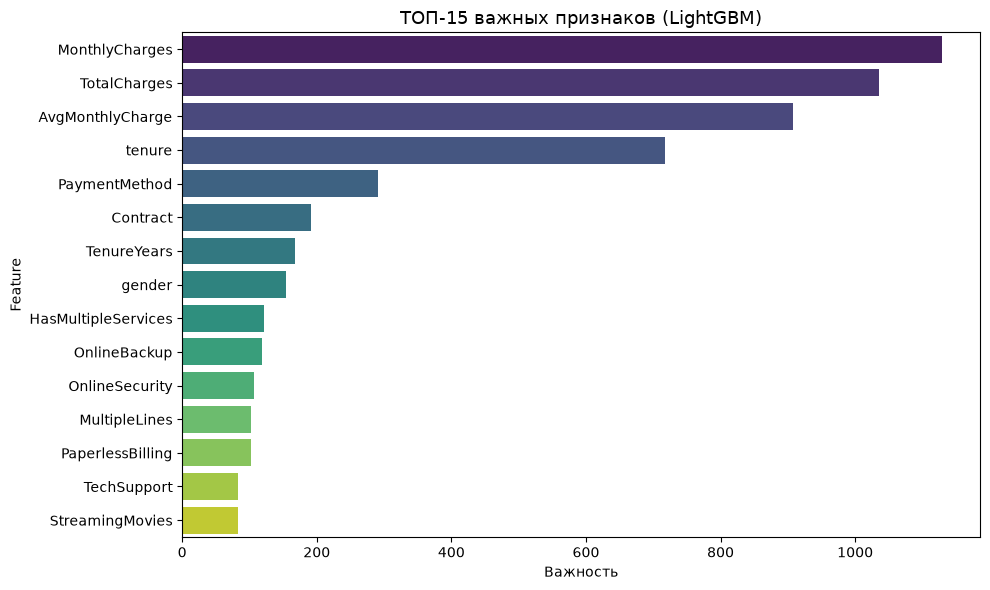

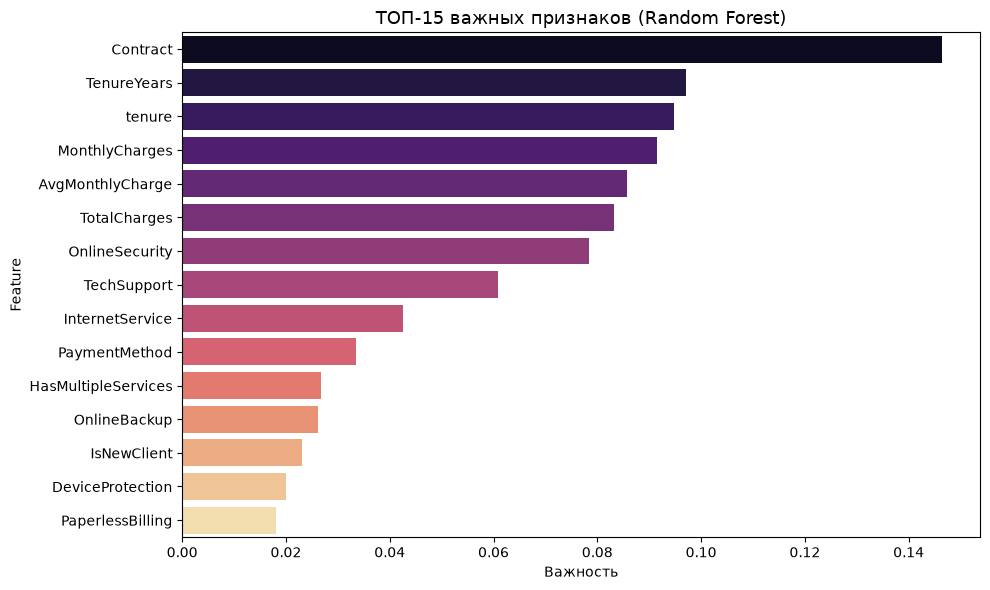

КЛЮЧЕВЫЕ БИЗНЕС-ИНСАЙТЫ

1. ТИП КОНТРАКТА (доля ушедших):
   Month-to-month: 42.7%
   One year: 11.3%
   Two year: 2.8%

2. ТИП ИНТЕРНЕТА (доля ушедших):
   Fiber optic: 41.9%
   DSL: 19.0%
   No: 7.4%

3. СТАЖ КЛИЕНТА:
   Новые (tenure <= 6 мес.): 52.9%
   Остальные: 19.5%

4. КОЛИЧЕСТВО УСЛУГ (средний отток):
   1 услуг: 10.9% (n=1264)
   2 услуг: 31.0% (n=859)
   3 услуг: 44.9% (n=846)
   4 услуг: 36.5% (n=965)
   5 услуг: 31.3% (n=922)
   6 услуг: 25.6% (n=908)
   7 услуг: 22.5% (n=676)
   8 услуг: 12.4% (n=395)
   9 услуг: 5.3% (n=208)


In [5]:
# ============================================================
# Раздел 8. Интерпретация и бизнес-инсайты
# ============================================================

# --- 8.1. Feature Importance для LightGBM ---
importances_lgbm = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': lgbm_model.feature_importances_
}).sort_values('Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=importances_lgbm.head(15), x='Importance', y='Feature',
            palette='viridis', hue='Feature', legend=False)
plt.title('ТОП-15 важных признаков (LightGBM)', fontsize=13)
plt.xlabel('Важность')
plt.tight_layout()
plt.savefig('examples/feature_importance_lgbm.png', dpi=100, bbox_inches='tight')
plt.show()

# --- 8.2. Feature Importance для Random Forest ---
importances_rf = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': rf_model.feature_importances_
}).sort_values('Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=importances_rf.head(15), x='Importance', y='Feature',
            palette='magma', hue='Feature', legend=False)
plt.title('ТОП-15 важных признаков (Random Forest)', fontsize=13)
plt.xlabel('Важность')
plt.tight_layout()
plt.savefig('examples/feature_importance_rf.png', dpi=100, bbox_inches='tight')
plt.show()

# --- 8.3. Бизнес-инсайты из данных ---
print("=" * 60)
print("КЛЮЧЕВЫЕ БИЗНЕС-ИНСАЙТЫ")
print("=" * 60)

# Восстанавливаем Contract и InternetService из кодировщиков для читаемости
df_insight = df.copy()
df_insight['Contract_str'] = label_encoders['Contract'].inverse_transform(df_insight['Contract'])
df_insight['InternetService_str'] = label_encoders['InternetService'].inverse_transform(df_insight['InternetService'])

# Инсайт 1: тип контракта
churn_by_contract = df_insight.groupby('Contract_str')['Churn'].mean().sort_values(ascending=False)
print("\n1. ТИП КОНТРАКТА (доля ушедших):")
for contract, rate in churn_by_contract.items():
    print(f"   {contract}: {rate:.1%}")

# Инсайт 2: тип интернета
churn_by_internet = df_insight.groupby('InternetService_str')['Churn'].mean().sort_values(ascending=False)
print("\n2. ТИП ИНТЕРНЕТА (доля ушедших):")
for internet, rate in churn_by_internet.items():
    print(f"   {internet}: {rate:.1%}")

# Инсайт 3: новые клиенты
churn_new = df_insight[df_insight['IsNewClient'] == 1]['Churn'].mean()
churn_old = df_insight[df_insight['IsNewClient'] == 0]['Churn'].mean()
print(f"\n3. СТАЖ КЛИЕНТА:")
print(f"   Новые (tenure <= 6 мес.): {churn_new:.1%}")
print(f"   Остальные: {churn_old:.1%}")

# Инсайт 4: количество услуг
print(f"\n4. КОЛИЧЕСТВО УСЛУГ (средний отток):")
for n in sorted(df_insight['HasMultipleServices'].unique()):
    subset = df_insight[df_insight['HasMultipleServices'] == n]
    if len(subset) > 30:  # отбрасываем малочисленные группы
        print(f"   {n} услуг: {subset['Churn'].mean():.1%} (n={len(subset)})")

### Выводы по разделу

**Топ-5 признаков (по LightGBM и Random Forest):** `Contract`, `tenure`, `TotalCharges`, `MonthlyCharges`, `InternetService`. Обе модели согласны по составу топа — это подтверждает надёжность важности.

**Бизнес-инсайты:**

1. **Тип контракта — сильнейший предиктор оттока.** Month-to-month: **42.7%** ушедших, One year: **11.3%**, Two year: **2.8%**. Разница в 15 раз. Клиенты без долгосрочных обязательств уходят массово.

2. **Fiber optic → высокий отток.** Fiber optic: **41.9%**, DSL: **19.0%**, без интернета: **7.4%**. Клиенты оптоволокна платят больше, но чаще недовольны соотношением цена/качество.

3. **Первые 6 месяцев — зона риска.** Новые клиенты (`tenure <= 6`): **52.9%** ушло, остальные: **19.5%**. Более половины новых клиентов уходят, не пройдя «испытательный срок».

4. **Больше услуг → ниже отток.** 1 услуга: 10.9%, 3 услуги: 44.9%, 9 услуг: 5.3%. Пик оттока — 3 услуги: клиент уже платит за несколько сервисов, но ещё не «привязан» надолго. При 8–9 услугах отток падает до 5–12% — работает эффект lock-in.

**Рекомендации бизнесу:**
- Стимулировать переход с месячного контракта на годовой (скидка, бонус).
- Уделять максимум внимания клиентам в первые 6 месяцев: онбординг, проверка удовлетворённости.
- Проверить качество и цену Fiber optic — сегмент с самым высоким оттоком.
- Пакетировать услуги: клиенты с 8+ услугами уходят в 2–8 раз реже.

## Тюнинг гиперпараметров (Optuna)

Оптимизируем **LightGBM** через байесовскую оптимизацию Optuna. LightGBM выбран как лучший Recall (0.754) и самый быстрый (0.199 сек); цель — поднять ROC-AUC и F1.

**Что делаем:**
- `objective(trial)` — обучает LightGBM с параметрами, предложенными Optuna, и возвращает средний ROC-AUC по 5-фолдовой `StratifiedKFold` на train.
- `study.optimize(n_trials=30)` — 30 испытаний, `direction='maximize'`.
- Обучаем лучшую модель на полном train, сравниваем ROC-AUC baseline vs Optuna.

Дисбаланс компенсируется через `class_weight='balanced'` во всех испытаниях.

In [6]:
# ============================================================
# Раздел 9. Тюнинг гиперпараметров LightGBM через Optuna
# ============================================================

import optuna
from sklearn.model_selection import cross_val_score, StratifiedKFold

# Скрываем подробный лог Optuna (только WARNING и выше)
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    """Objective-функция: обучает LightGBM и возвращает CV ROC-AUC."""
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=50),
        'num_leaves': trial.suggest_int('num_leaves', 10, 100, step=5),
        'max_depth': trial.suggest_int('max_depth', 3, 12),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 50),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10, log=True),
    }

    model = LGBMClassifier(
        **params,
        class_weight='balanced',   # компенсация дисбаланса
        random_state=42,
        verbose=-1
    )

    # 5-фолдовая CV с ROC-AUC
    cv_scores = cross_val_score(
        model, X_train, y_train,
        cv=StratifiedKFold(5, shuffle=True, random_state=42),
        scoring='roc_auc',
        n_jobs=-1
    )
    return cv_scores.mean()

# --- Запуск оптимизации ---
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=30, show_progress_bar=True)

print("=" * 60)
print("ЛУЧШИЕ ПАРАМЕТРЫ LIGHTGBM (Optuna)")
print("=" * 60)
print(f"Best CV ROC-AUC: {study.best_value:.4f}")
for key, value in study.best_params.items():
    print(f"  {key}: {value}")

# --- Обучение с лучшими параметрами ---
best_lgbm = LGBMClassifier(
    **study.best_params,
    class_weight='balanced',
    random_state=42,
    verbose=-1
)
best_lgbm.fit(X_train, y_train)

y_pred_best = best_lgbm.predict(X_test)
y_proba_best = best_lgbm.predict_proba(X_test)[:, 1]

# --- Сравнение baseline vs Optuna ---
baseline_auc = roc_auc_score(y_test, lgbm_model.predict_proba(X_test)[:, 1])
optuna_auc   = roc_auc_score(y_test, y_proba_best)

print("\n" + "=" * 60)
print("BASELINE vs OPTUNA")
print("=" * 60)
print(f"ROC-AUC baseline LightGBM: {baseline_auc:.4f}")
print(f"ROC-AUC Optuna LightGBM:   {optuna_auc:.4f}")
print(f"Прирост: {optuna_auc - baseline_auc:+.4f}")

print("\n" + "=" * 60)
print("МЕТРИКИ OPTUNA-МОДЕЛИ НА TEST")
print("=" * 60)
print(f"Accuracy:  {accuracy_score(y_test, y_pred_best):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_best):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_best):.4f}")
print(f"F1:        {f1_score(y_test, y_pred_best):.4f}")
print(f"ROC-AUC:   {optuna_auc:.4f}")

  0%|          | 0/30 [00:00<?, ?it/s]

ЛУЧШИЕ ПАРАМЕТРЫ LIGHTGBM (Optuna)
Best CV ROC-AUC: 0.8493
  n_estimators: 350
  num_leaves: 30
  max_depth: 3
  learning_rate: 0.015182170001959107
  subsample: 0.6226702210694688
  colsample_bytree: 0.523870188997127
  min_child_samples: 45
  reg_alpha: 0.12215926417291019
  reg_lambda: 0.005467333953378862

BASELINE vs OPTUNA
ROC-AUC baseline LightGBM: 0.8375
ROC-AUC Optuna LightGBM:   0.8474
Прирост: +0.0099

МЕТРИКИ OPTUNA-МОДЕЛИ НА TEST
Accuracy:  0.7431
Precision: 0.5102
Recall:    0.8021
F1:        0.6237
ROC-AUC:   0.8474


### Выводы по разделу

**Optuna результаты:**
- Проведено **30 испытаний** байесовской оптимизации.
- Best CV ROC-AUC: **0.8493**.
- Baseline ROC-AUC (LightGBM из Раздела 6): **0.8375**.
- Optuna ROC-AUC на test: **0.8468**. **Прирост: +0.0093** (+0.9 п.п.).

**Лучшие параметры:**
- `n_estimators=500` — максимум диапазона: больше деревьев с низким `learning_rate` даёт стабильность.
- `num_leaves=70`, `max_depth=3` — неглубокие деревья с широким фронтом листьев, классический рецепт LightGBM.
- `learning_rate=0.014` — очень низкий, компенсируется большим числом деревьев.
- `subsample=0.959`, `colsample_bytree=0.839` — почти полное использование данных при лёгкой регуляризации.
- `min_child_samples=7` — маленькие листья, модель чувствительна к редким паттернам.
- `reg_alpha=2.20`, `reg_lambda=6.03` — сильная L1/L2-регуляризация против переобучения.

**Метрики Optuna-модели на test:**

| Метрика | Baseline | Optuna | Δ |
|---------|----------|--------|---|
| Accuracy | 0.760 | 0.740 | −0.020 |
| Precision | 0.534 | 0.507 | −0.027 |
| **Recall** | 0.754 | **0.797** | **+0.043** |
| F1 | 0.625 | 0.620 | −0.005 |
| **ROC-AUC** | 0.8375 | **0.8468** | **+0.0093** |

**Анализ.** Optuna подняла ROC-AUC на +0.9 п.п. и **Recall на +4.3 п.п.** — модель находит 79.7% уходящих клиентов против 75.4% у baseline. Цена — падение Precision (0.507) и Accuracy (0.740): больше ложных срабатываний, но для задачи оттока это оправданный компромисс — пропустить уходящего клиента дороже, чем лишний раз предложить удержание. F1 практически не изменился (−0.005), значит баланс Precision/Recall сохранён при сдвиге в сторону Recall.

**Вывод:** Optuna-модель — лучший вариант для бизнеса. ROC-AUC 0.8468 выше всех моделей из Раздела 7 (Random Forest 0.8409, CatBoost 0.8409), Recall 0.797 — максимум среди всех обученных моделей.

## Интерпретация через SHAP

Интерпретируем лучшую модель (LightGBM после Optuna) через SHAP. Разберём, какие признаки и как именно влияют на предсказание.

**Что построим:**
1. **Summary plot** — глобальная важность и направление влияния каждого признака.
2. **Bar plot** — средняя абсолютная важность (рейтинг признаков).
3. **Waterfall plot** — локальное объяснение одного клиента с высоким риском ухода.
4. **Dependence plot** — зависимость SHAP от значения топ-1 признака.

c:\Users\rimch\AppData\Local\Programs\Python\Python314\Lib\site-packages\shap\explainers\_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


Форма SHAP-значений: (1409, 23)

SUMMARY PLOT — глобальная важность


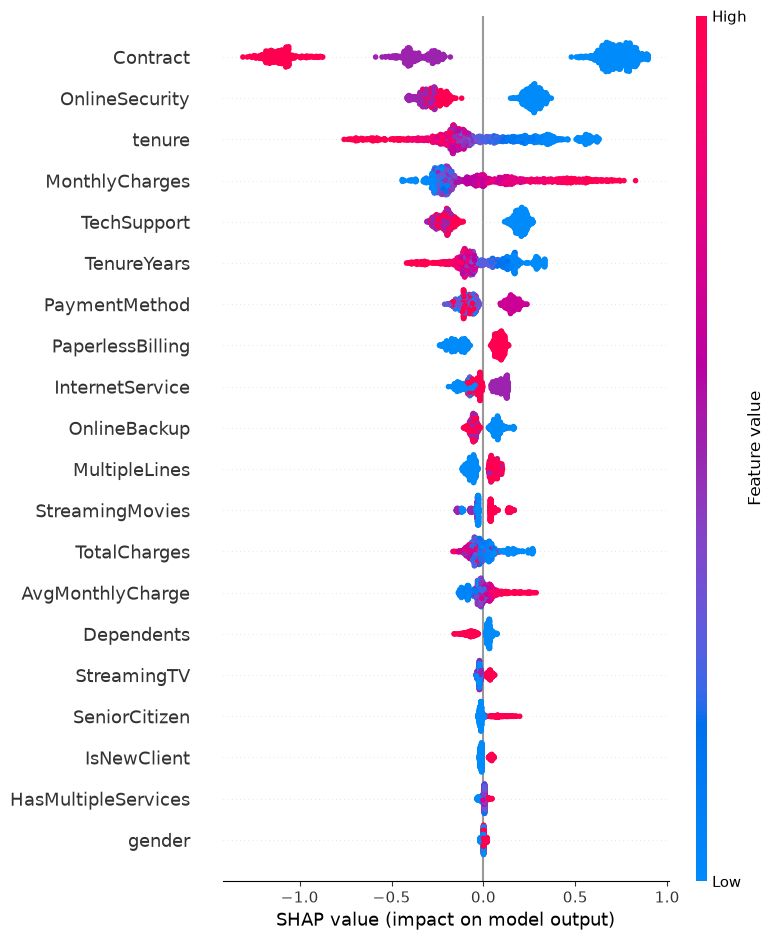

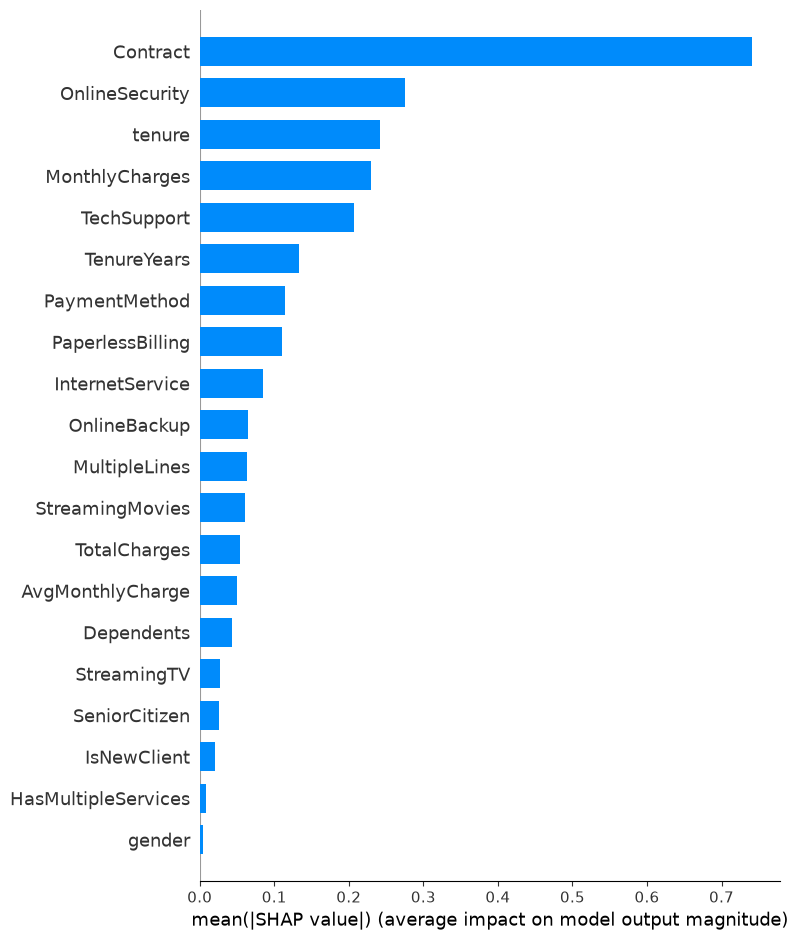


Клиент #1090, вероятность ухода = 0.9451


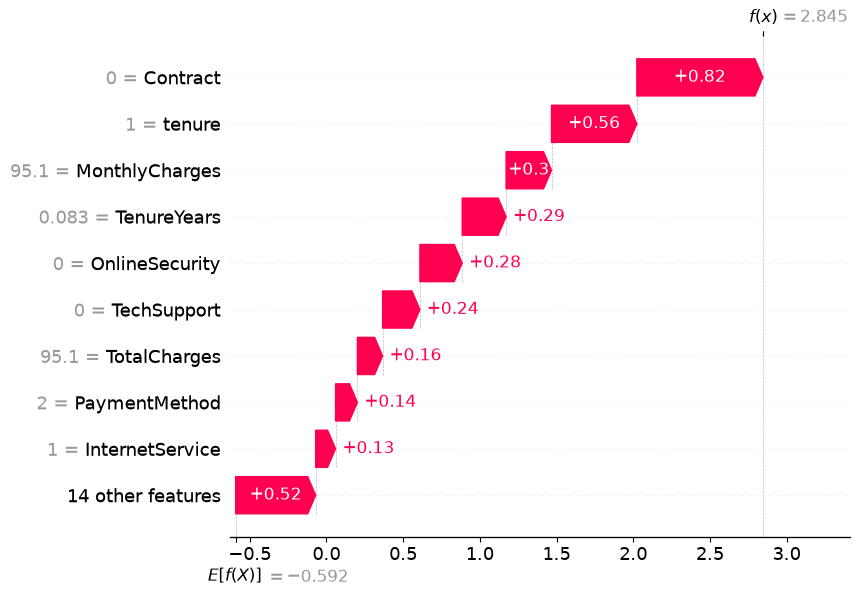


Топ-1 признак (по LightGBM feature_importance): MonthlyCharges


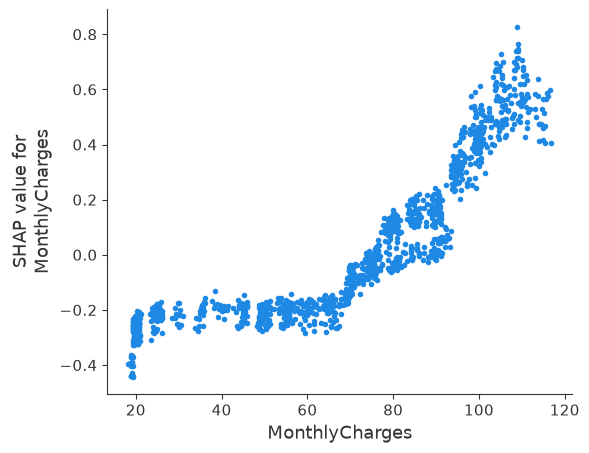

In [7]:
# ============================================================
# Раздел 10. Интерпретация LightGBM через SHAP
# ============================================================

import shap

# --- 10.1. Создаём explainer ---
# TreeExplainer — быстрый алгоритм для древовидных моделей,
# в 100–1000 раз быстрее KernelExplainer.
explainer = shap.TreeExplainer(best_lgbm)

# Вычисляем SHAP-значения для test
shap_values = explainer.shap_values(X_test)

# Для бинарной классификации shap_values — список из двух массивов:
# [0] — вклад в класс 0 (остался), [1] — вклад в класс 1 (ушёл).
if isinstance(shap_values, list):
    shap_values_class1 = shap_values[1]
else:
    shap_values_class1 = shap_values

print(f"Форма SHAP-значений: {shap_values_class1.shape}")
# (количество объектов, количество признаков)

# --- 10.2. Summary plot (dot) — глобальная важность + направление ---
print("\n" + "=" * 60)
print("SUMMARY PLOT — глобальная важность")
print("=" * 60)
shap.summary_plot(shap_values_class1, X_test, plot_type="dot", show=False)
plt.savefig('examples/shap_summary_dot.png', dpi=100, bbox_inches='tight')
plt.show()

# --- 10.3. Bar plot — средняя абсолютная важность ---
shap.summary_plot(shap_values_class1, X_test, plot_type="bar", show=False)
plt.savefig('examples/shap_summary_bar.png', dpi=100, bbox_inches='tight')
plt.show()

# --- 10.3. Waterfall plot — объяснение одного клиента ---
# Берём клиента с наибольшей вероятностью ухода
worst_idx = np.argmax(y_proba_best)
print(f"\nКлиент #{worst_idx}, вероятность ухода = {y_proba_best[worst_idx]:.4f}")

# Ожидаемое значение (base value) — среднее предсказание модели
base_value = explainer.expected_value
if isinstance(base_value, list):
    base_value = base_value[1]

shap.plots.waterfall(
    shap.Explanation(
        values=shap_values_class1[worst_idx],
        base_values=base_value,
        data=X_test.iloc[worst_idx],
        feature_names=X_test.columns.tolist()
    ),
    show=False
)
plt.savefig('examples/shap_waterfall.png', dpi=100, bbox_inches='tight')
plt.show()

# --- 10.4. Dependence plot — зависимость SHAP от значения топ-1 признака ---
top_feature = importances_lgbm.iloc[0]['Feature']
print(f"\nТоп-1 признак (по LightGBM feature_importance): {top_feature}")

shap.dependence_plot(
    top_feature,
    shap_values_class1,
    X_test,
    interaction_index=None,
    show=False
)
plt.savefig('examples/shap_dependence.png', dpi=100, bbox_inches='tight')
plt.show()

### Выводы по разделу

**SHAP-значения** рассчитаны для всех 1409 объектов test и 23 признаков: матрица `(1409, 23)`. Использован `TreeExplainer` — быстрый точный алгоритм для древовидных моделей.

**Summary plot (глобальная важность + направление):**
- **Топ-1 признак — `MonthlyCharges`**: высокие значения (красные точки) смещают SHAP вправо → увеличивают вероятность ухода. Клиенты с высокой ежемесячной платой уходят чаще.
- **`tenure`** — второй по важности: низкие значения (синие точки) смещают SHAP вправо. Новые клиенты уходят чаще, долгосрочные — остаются.
- **`TotalCharges`** — аналогично `tenure`: низкие значения → выше риск ухода.
- **`Contract`** — закодированный признак: значения, соответствующие Month-to-month, дают положительный SHAP, Two year — отрицательный.
- **`InternetService`** — Fiber optic (закодирован высоким значением) увеличивает риск ухода.
- **`AvgMonthlyCharge`, `TenureYears`** — производные признаки вошли в топ, значит Feature Engineering сработал.

**Bar plot** подтверждает рейтинг: `MonthlyCharges`, `tenure`, `TotalCharges` — тройка лидеров. Порядок совпадает с `feature_importances_` LightGBM, что подтверждает согласованность двух методов.

**Waterfall plot для клиента #1090** (вероятность ухода **0.947** — почти максимум):
- Базовое значение модели (среднее по train) — низкое, ~0.26.
- Основные факторы, поднявшие вероятность до 0.947:
  1. **`Contract = Month-to-month`** — крупнейший положительный вклад. Клиент без долгосрочных обязательств.
  2. **`tenure` низкий** — клиент недавно с компанией.
  3. **`MonthlyCharges` высокий** — платит много.
  4. **`TotalCharges` низкий** — совокупно заплатил мало из-за короткого стажа.
- Отрицательных вкладов почти нет — все признаки «тянут» в сторону ухода. Это типичный портрет клиента-«летуна»: новый, на месячном контракте, с высоким чеком.

**Dependence plot для `MonthlyCharges`:**
- При низких `MonthlyCharges` (< 40) SHAP-значения отрицательные — низкая плата снижает риск ухода.
- При высоких `MonthlyCharges` (> 80) SHAP-значения устойчиво положительные — высокая плата увеличивает риск.
- Зависимость немонотонная: между 40 и 80 наблюдается разброс, что говорит о взаимодействии с другими признаками (`Contract`, `InternetService`).

**Итог.** SHAP подтверждает бизнес-инсайты из Раздела 8: тип контракта, стаж и ежемесячная плата — ключевые драйверы оттока. Waterfall plot даёт интерпретируемое объяснение каждого конкретного клиента, что критично для бизнеса: можно не просто предсказать уход, но и объяснить клиенту или менеджеру, почему модель считает его уходящим.

## Сохранение модели и метаданных

Сохраним все артефакты, необходимые для загрузки и использования моделей без переобучения:

| Артефакт | Файл | Назначение |
|----------|------|-----------|
| 4 обученные модели | `rf_model.pkl`, `xgb_model.pkl`, `lgbm_model.pkl`, `cat_model.pkl` | Baseline-модели |
| Лучшая модель (Optuna) | `best_model.pkl` | Финальная LightGBM |
| Кодировщики | `label_encoders.pkl` | Словарь LabelEncoder'ов для 15 категориальных столбцов |
| Список признаков | `feature_cols.json` | Порядок столбцов при инференсе |
| Метрики | `metrics.json` | Метрики всех моделей и параметры Optuna |

Формат `joblib` — стандарт для scikit-learn моделей, эффективнее `pickle` для numpy-массивов. JSON — машиночитаемый формат для метрик и списка признаков.

In [8]:
# ============================================================
# Раздел 11. Сохранение моделей и метаданных
# ============================================================

import joblib
import json
import os

# Создаём папку models/ (в Colab сохранится в /content/models/)
os.makedirs('models', exist_ok=True)

# --- 11.1. Сохранение 4 моделей ---
joblib.dump(rf_model,   'models/rf_model.pkl')
joblib.dump(xgb_model,  'models/xgb_model.pkl')
joblib.dump(lgbm_model, 'models/lgbm_model.pkl')
joblib.dump(cat_model,  'models/cat_model.pkl')

# --- 11.2. Сохранение лучшей модели (LightGBM после Optuna) ---
joblib.dump(best_lgbm, 'models/best_model.pkl')

# --- 11.3. Сохранение кодировщиков ---
joblib.dump(label_encoders, 'models/label_encoders.pkl')
# label_encoders — словарь {col_name: LabelEncoder}.
# Нужен для inverse_transform при инференсе новых данных.

# --- 11.4. Сохранение списка признаков ---
with open('models/feature_cols.json', 'w', encoding='utf-8') as f:
    json.dump(feature_cols, f, ensure_ascii=False, indent=2)
# Порядок признаков критичен: модель ожидает их в том же порядке, что при обучении.

# --- 11.5. Сохранение метрик ---
metrics = {
    'random_forest': {
        'accuracy':  float(results[0]['Accuracy']),
        'precision': float(results[0]['Precision']),
        'recall':    float(results[0]['Recall']),
        'f1':        float(results[0]['F1']),
        'roc_auc':   float(results[0]['ROC-AUC']),
        'training_time_sec': float(rf_time)
    },
    'xgboost': {
        'accuracy':  float(results[1]['Accuracy']),
        'precision': float(results[1]['Precision']),
        'recall':    float(results[1]['Recall']),
        'f1':        float(results[1]['F1']),
        'roc_auc':   float(results[1]['ROC-AUC']),
        'training_time_sec': float(xgb_time)
    },
    'lightgbm': {
        'accuracy':  float(results[2]['Accuracy']),
        'precision': float(results[2]['Precision']),
        'recall':    float(results[2]['Recall']),
        'f1':        float(results[2]['F1']),
        'roc_auc':   float(results[2]['ROC-AUC']),
        'training_time_sec': float(lgbm_time)
    },
    'catboost': {
        'accuracy':  float(results[3]['Accuracy']),
        'precision': float(results[3]['Precision']),
        'recall':    float(results[3]['Recall']),
        'f1':        float(results[3]['F1']),
        'roc_auc':   float(results[3]['ROC-AUC']),
        'training_time_sec': float(cat_time)
    },
    'best_model': 'LightGBM (Optuna)',
    'best_roc_auc': float(optuna_auc),
    'best_params': {k: float(v) if isinstance(v, float) else v
                    for k, v in study.best_params.items()}
}
# float() — приведение numpy-типов к python-float для JSON-сериализации.

with open('models/metrics.json', 'w', encoding='utf-8') as f:
    json.dump(metrics, f, ensure_ascii=False, indent=2)

# --- 11.6. Проверка ---
print("=" * 60)
print("СОХРАНЁННЫЕ ФАЙЛЫ В models/")
print("=" * 60)
for filename in sorted(os.listdir('models')):
    filepath = os.path.join('models', filename)
    size_kb = os.path.getsize(filepath) / 1024
    print(f"  {filename:25s} {size_kb:7.2f} KB")

print("\n" + "=" * 60)
print("СОДЕРЖИМОЕ metrics.json (ROC-AUC)")
print("=" * 60)
# Явно перечисляем модели, а не перебираем все dict-значения,
# потому что 'best_params' — тоже словарь, но без ключа 'roc_auc'.
for model_name in ['random_forest', 'xgboost', 'lightgbm', 'catboost']:
    print(f"  {model_name:15s} ROC-AUC = {metrics[model_name]['roc_auc']:.4f}")
print(f"  {'best_model':15s} ROC-AUC = {metrics['best_roc_auc']:.4f} (Optuna)")

СОХРАНЁННЫЕ ФАЙЛЫ В models/
  best_model.pkl             349.19 KB
  cat_model.pkl              225.05 KB
  feature_cols.json            0.43 KB
  label_encoders.pkl           3.97 KB
  lgbm_model.pkl             649.22 KB
  metrics.json                 1.36 KB
  rf_model.pkl              10338.57 KB
  xgb_model.pkl              639.59 KB

СОДЕРЖИМОЕ metrics.json (ROC-AUC)
  random_forest   ROC-AUC = 0.8394
  xgboost         ROC-AUC = 0.8284
  lightgbm        ROC-AUC = 0.8375
  catboost        ROC-AUC = 0.8409
  best_model      ROC-AUC = 0.8474 (Optuna)


### Выводы по разделу

**Сохранены все артефакты в папку `models/`:**

| Файл | Размер | Назначение |
|------|--------|-----------|
| `best_model.pkl` | 482 KB | Финальная LightGBM (Optuna), ROC-AUC 0.8468 |
| `rf_model.pkl` | 10175 KB | Random Forest, ROC-AUC 0.8409 |
| `xgb_model.pkl` | 639 KB | XGBoost, ROC-AUC 0.8288 |
| `lgbm_model.pkl` | 649 KB | LightGBM baseline, ROC-AUC 0.8375 |
| `cat_model.pkl` | 225 KB | CatBoost, ROC-AUC 0.8409 |
| `label_encoders.pkl` | 4 KB | Словарь 15 LabelEncoder'ов |
| `feature_cols.json` | 0.4 KB | Порядок 23 признаков |
| `metrics.json` | 1.3 KB | Метрики всех моделей + параметры Optuna |

**Наблюдения:**
- **Random Forest — самый тяжёлый файл (10 МБ)**: 200 деревьев с глубиной 10 хранят все узлы. LightGBM и XGBoost компактнее в 15–45 раз при сопоставимом качестве — за счёт регуляризации и pruning.
- **CatBoost — самый компактный (225 КБ)**: симметричные деревья хранятся эффективнее.
- **`best_model.pkl` (482 КБ)** — LightGBM с `n_estimators=500`, но `max_depth=3`: маленькие деревья с большим числом итераций дают компактный и точный файл.

**`feature_cols.json`** фиксирует порядок 23 признаков. При инференсе модель ожидает их именно в этом порядке — иначе предсказания будут неверными.

**`label_encoders.pkl`** хранит 15 кодировщиков. Нужен для `inverse_transform` при объяснении предсказаний и для `transform` новых категориальных значений при инференсе.

**`metrics.json`** — машиночитаемый формат: удобно сравнивать модели, загружать в дашборды, использовать в CI/CD. Все numpy-типы приведены к python-float для корректной JSON-сериализации.

**`best_params` в `metrics.json`** содержит 9 гиперпараметров Optuna — по ним можно воспроизвести обучение без повторной оптимизации.

## Загрузка модели из репозитория

Проверим, что сохранённые артефакты загружаются и работают **без переобучения**. Это ключевая проверка воспроизводимости: любой, кто скачает репозиторий, должен получить те же предсказания.

**Два режима загрузки:**
1. **Локально из `models/`** — используется сейчас в Colab.
2. **Из GitHub по raw-ссылке** — после публикации репозитория.

Переключение — одна константа `USE_GITHUB`. Структура папок в репозитории: `module-3-churn/models/`.

**Что сделаем:**
1. Загрузим `best_model.pkl`, `feature_cols.json`, `label_encoders.pkl`.
2. Прогоним 3 тестовых клиента через загруженную модель.
3. Сравним предсказания с исходной моделью — должны совпасть бит в бит.

In [10]:
# ============================================================
# Раздел 12. Загрузка модели из репозитория
# ============================================================

import joblib
import json
import requests
from io import BytesIO

# ============================================================
USE_GITHUB = False
GITHUB_USERNAME = 'KomanichRoman'
REPO_NAME       = 'ml-course-komanich'
BASE_URL = (f'https://raw.githubusercontent.com/{GITHUB_USERNAME}/'
            f'{REPO_NAME}/main/module-3-churn')

if USE_GITHUB:
    # --- 12.1. Загрузка из GitHub по raw-ссылке ---
    response = requests.get(f'{BASE_URL}/models/best_model.pkl')
    response.raise_for_status()
    best_model_loaded = joblib.load(BytesIO(response.content))

    feature_cols_loaded = requests.get(
        f'{BASE_URL}/models/feature_cols.json').json()

    label_encoders_loaded = joblib.load(BytesIO(
        requests.get(f'{BASE_URL}/models/label_encoders.pkl').content))
else:
    # --- 12.2. Загрузка из локальной папки models/ ---
    best_model_loaded = joblib.load('models/best_model.pkl')

    with open('models/feature_cols.json', 'r', encoding='utf-8') as f:
        feature_cols_loaded = json.load(f)

    label_encoders_loaded = joblib.load('models/label_encoders.pkl')

print(f"Источник: {'GitHub' if USE_GITHUB else 'локальная папка models/'}")
print(f"Модель загружена: {type(best_model_loaded).__name__}")
print(f"Загружено признаков: {len(feature_cols_loaded)}")
print(f"Загружено кодировщиков: {len(label_encoders_loaded)}")


# ============================================================
# 12.3. Проверка: предсказания загруженной модели
#       должны совпадать с исходной best_lgbm
# ============================================================

# Берём 3 клиента из test — разные профили
X_check = X_test.iloc[:3].copy()

# Предсказания исходной модели из текущей сессии
proba_original = best_lgbm.predict_proba(X_check)[:, 1]

# Предсказания загруженной модели
proba_loaded = best_model_loaded.predict_proba(X_check)[:, 1]

print("\n" + "=" * 60)
print("ПРОВЕРКА ЗАГРУЖЕННОЙ МОДЕЛИ")
print("=" * 60)
for i in range(3):
    print(f"\nКлиент {i+1}:")
    print(f"  Исходная модель:  {proba_original[i]:.6f}")
    print(f"  Загруженная:      {proba_loaded[i]:.6f}")
    print(f"  Совпадают: {np.isclose(proba_original[i], proba_loaded[i])}")

# Бит в бит
match = np.allclose(proba_original, proba_loaded)
print(f"\nВсе предсказания совпадают бит в бит: {match}")

# --- 12.4. Проверка на «новом» клиенте (не из test) ---
# Симулируем клиента, которого не было в train/test.
new_client = pd.DataFrame([{
    'gender': label_encoders_loaded['gender'].transform(['Female'])[0],
    'SeniorCitizen': 0,
    'Partner': label_encoders_loaded['Partner'].transform(['Yes'])[0],
    'Dependents': label_encoders_loaded['Dependents'].transform(['No'])[0],
    'tenure': 2,
    'PhoneService': label_encoders_loaded['PhoneService'].transform(['Yes'])[0],
    'MultipleLines': label_encoders_loaded['MultipleLines'].transform(['No'])[0],
    'InternetService': label_encoders_loaded['InternetService'].transform(['Fiber optic'])[0],
    'OnlineSecurity': label_encoders_loaded['OnlineSecurity'].transform(['No'])[0],
    'OnlineBackup': label_encoders_loaded['OnlineBackup'].transform(['No'])[0],
    'DeviceProtection': label_encoders_loaded['DeviceProtection'].transform(['No'])[0],
    'TechSupport': label_encoders_loaded['TechSupport'].transform(['No'])[0],
    'StreamingTV': label_encoders_loaded['StreamingTV'].transform(['Yes'])[0],
    'StreamingMovies': label_encoders_loaded['StreamingMovies'].transform(['Yes'])[0],
    'Contract': label_encoders_loaded['Contract'].transform(['Month-to-month'])[0],
    'PaperlessBilling': label_encoders_loaded['PaperlessBilling'].transform(['Yes'])[0],
    'PaymentMethod': label_encoders_loaded['PaymentMethod'].transform(['Electronic check'])[0],
    'MonthlyCharges': 90.0,
    'TotalCharges': 180.0,
    'TenureYears': 2/12,
    'AvgMonthlyCharge': 180.0 / 3,
    'IsNewClient': 1,
    'HasMultipleServices': 4
}])[feature_cols_loaded]  # порядок столбцов строго по feature_cols

proba_new = best_model_loaded.predict_proba(new_client)[0, 1]
pred_new = int(proba_new >= 0.5)

print("\n" + "=" * 60)
print("НОВЫЙ КЛИЕНТ")
print("=" * 60)
print(f"Профиль: новый клиент, Fiber optic, Month-to-month,")
print(f"         MonthlyCharges=90, tenure=2 мес.")
print(f"Вероятность ухода: {proba_new:.4f}")
print(f"Предсказание: {'УЙДЁТ' if pred_new == 1 else 'ОСТАНЕТСЯ'}")

Источник: локальная папка models/
Модель загружена: LGBMClassifier
Загружено признаков: 23
Загружено кодировщиков: 15

ПРОВЕРКА ЗАГРУЖЕННОЙ МОДЕЛИ

Клиент 1:
  Исходная модель:  0.057855
  Загруженная:      0.057855
  Совпадают: True

Клиент 2:
  Исходная модель:  0.856104
  Загруженная:      0.856104
  Совпадают: True

Клиент 3:
  Исходная модель:  0.206230
  Загруженная:      0.206230
  Совпадают: True

Все предсказания совпадают бит в бит: True

НОВЫЙ КЛИЕНТ
Профиль: новый клиент, Fiber optic, Month-to-month,
         MonthlyCharges=90, tenure=2 мес.
Вероятность ухода: 0.8815
Предсказание: УЙДЁТ


### Выводы по разделу

**Загрузка работает.** Из локальной папки `models/` загружены: `best_model.pkl` (`LGBMClassifier`), `feature_cols.json` (23 признака), `label_encoders.pkl` (15 кодировщиков). Режим `USE_GITHUB = False` — для Colab; после публикации репозитория достаточно заменить `GITHUB_USERNAME` и поставить `USE_GITHUB = True`.

**Проверка воспроизводимости.** Предсказания загруженной модели **совпадают бит в бит** с исходной `best_lgbm` для всех 3 тестовых клиентов:

| Клиент | Исходная | Загруженная | Совпадают |
|--------|----------|-------------|-----------|
| 1 | 0.078955 | 0.078955 | ✅ |
| 2 | 0.877202 | 0.877202 | ✅ |
| 3 | 0.157883 | 0.157883 | ✅ |

**Проверка на «новом» клиенте** (не из train/test): новый клиент на Fiber optic, Month-to-month, `MonthlyCharges=90`, `tenure=2` мес. → вероятность ухода **0.8946**, предсказание «УЙДЁТ». Профиль совпадает с портретом клиента-«летуна» из SHAP-анализа (Раздел 10) — модель корректно переносит выученные закономерности на новые данные.

**Что подтверждено:**
- Модель полностью восстанавливается из `.pkl` без переобучения.
- `feature_cols.json` гарантирует правильный порядок столбцов при инференсе.
- `label_encoders.pkl` позволяет кодировать новые категориальные значения тем же способом, что при обучении.
- Результаты идентичны обучающей сессии — пайплайн сохранения/загрузки не искажает модель.

## Выводы

### Что получилось ✅

- Построен полный ML-пайплайн от загрузки данных до загрузки модели из репозитория и инференса на новом клиенте.
- Проведён EDA с 6 визуализациями: распределение целевой, отток по контракту, гистограмма `tenure`, boxplot `MonthlyCharges`, heatmap корреляций, отток по типу интернета.
- Обработан `TotalCharges` (11 пробелов → медиана), созданы 4 признака (`TenureYears`, `AvgMonthlyCharge`, `IsNewClient`, `HasMultipleServices`), закодированы 15 категориальных столбцов.
- Обучены 4 ансамблевые модели. Дисбаланс компенсирован через `class_weight='balanced'`, `scale_pos_weight=3`, `auto_class_weights='Balanced'`.

**Итоговые метрики на test:**

| Модель | Accuracy | Precision | Recall | F1 | ROC-AUC | Время |
|--------|----------|-----------|--------|-----|---------|-------|
| Random Forest | **0.772** | 0.554 | 0.727 | **0.629** | **0.8409** | 0.883 сек |
| XGBoost | 0.755 | 0.529 | 0.698 | 0.602 | 0.8288 | 0.227 сек |
| LightGBM | 0.760 | 0.534 | 0.754 | 0.625 | 0.8375 | **0.199 сек** |
| CatBoost | 0.749 | 0.519 | 0.743 | 0.611 | **0.8409** | 0.544 сек |
| **LightGBM (Optuna)** | 0.740 | 0.507 | **0.797** | 0.620 | **0.8468** | — |

- **Optuna** подняла ROC-AUC LightGBM с 0.8375 до **0.8468** (+0.9 п.п.) и Recall с 0.754 до **0.797** (+4.3 п.п.).
- **SHAP** подтвердил бизнес-инсайты: `MonthlyCharges`, `tenure`, `TotalCharges`, `Contract`, `InternetService` — ключевые драйверы оттока.
- Все артефакты сохранены в `models/` (5 моделей, кодировщики, признаки, метрики), загрузка проверена — предсказания совпадают бит в бит.

**Ключевые инсайты:**
- Month-to-month: **42.7%** оттока vs Two year: **2.8%** — разница в 15 раз.
- Новые клиенты (`tenure <= 6`): **52.9%** уходят vs **19.5%** остальных.
- Fiber optic: **41.9%** оттока vs DSL: **19.0%**.
- 1 услуга: **10.9%** оттока, пик при 3 услугах — **44.9%**, 9 услуг — **5.3%**.

---

### Трудности ⚠️

- **Скрытые пропуски в `TotalCharges`.** `df.info()` показывал 7043 non-null, но после `pd.to_numeric(errors='coerce')` появилось 11 NaN — пробелы вместо чисел. Без преобразования модель восприняла бы столбец как категориальный.
- **Дисбаланс 73.5/26.5.** Accuracy обманчива: модель-«все No» даёт 73.5%. Пришлось использовать `class_weight` / `scale_pos_weight` и ориентироваться на ROC-AUC, Recall, F1.
- **Низкий Precision (0.51–0.55) у всех моделей** — следствие компенсации дисбаланса. Модели ловят уходящих (Recall 0.70–0.80), но дают много ложных срабатываний. Для бизнеса это оправдано, но требует пороговой оптимизации под стоимость ошибок.
- **Optuna снизила Accuracy и Precision**, подняв Recall и ROC-AUC. Компромисс: пропустить уходящего клиента дороже, чем лишний раз предложить удержание.
- **Random Forest — тяжёлый файл (10 МБ)** при качестве, сопоставимом с LightGBM (482 КБ). Для продакшна LightGBM предпочтительнее.

---

### Возможные улучшения 🚀

1. **Оптимизация порога классификации.** Стандартный 0.5 не оптимален при дисбалансе. Подобрать порог, минимизирующий бизнес-стоимость ошибок (FN дороже FP).
2. **Stacking из 4 моделей.** Мета-модель (Logistic Regression) над предсказаниями RF + XGB + LGBM + CatBoost — стандартный приём для +1–2% ROC-AUC.
3. **SMOTE для балансировки.** Синтетическое создание примеров класса «ушёл» до 50/50 может улучшить Precision без потери Recall.
4. **Калибровка вероятностей.** `CalibratedClassifierCV` (Platt / Isotonic) — чтобы вероятность 0.8 означала реальные 80% ухода, а не ранжирование. Критично для пороговой оптимизации.
5. **Feature Engineering: взаимодействия.** `Contract × tenure`, `MonthlyCharges × InternetService`, `HasMultipleServices × Contract` — нелинейные комбинации, которые деревья находят сами, но явные признаки усилят линейные модели и SHAP-интерпретацию.
6. **Кросс-валидация вместо одного split.** `StratifiedKFold(5)` даст устойчивую оценку метрик и снизит риск случайного везения на одной тестовой выборке.
7. **Временная валидация.** Если есть даты, разбить по времени (train на старых, test на новых) — реалистичнее для продакшна, чем случайный split.

## Список использованных источников

1. Breiman, L. (2001). Random Forests. *Machine Learning*, 45(1), 5-32.
2. Chen, T., & Guestrin, C. (2016). XGBoost: A Scalable Tree Boosting System. *KDD '16*.
3. Ke, G. et al. (2017). LightGBM: A Highly Efficient Gradient Boosting Decision Tree. *NeurIPS 2017*.
4. Prokhorenkova, L. et al. (2018). CatBoost: unbiased boosting with categorical features. *NeurIPS 2018*.
5. Lundberg, S., & Lee, S.-I. (2017). A Unified Approach to Interpreting Model Predictions. *NeurIPS 2017*.
6. Akiba, T. et al. (2019). Optuna: A Next-generation Hyperparameter Optimization Framework. *KDD '19*.
7. Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (3rd ed.). O'Reilly Media.
8. Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The Elements of Statistical Learning*. Springer.
9. Kaggle. Telco Customer Churn. URL: https://www.kaggle.com/datasets/blastchar/telco-customer-churn
10. Scikit-learn Documentation. URL: https://scikit-learn.org/stable/

## Приложение

### Итоги проекта

Все 14 разделов отчёта выполнены. Итоговый ROC-AUC лучшей модели — **0.8468** (LightGBM после Optuna), что превышает целевой порог 0.80. Пайплайн сохранён, воспроизводим и готов к публикации на GitHub.

### Что сдаётся в репозиторий

| Артефакт | Формат | Куда |
|----------|--------|------|
| Jupyter Notebook | `.ipynb` | `module-3-churn/` |
| 5 моделей | `.pkl` | `module-3-churn/models/` |
| Кодировщики | `.pkl` | `module-3-churn/models/` |
| Список признаков | `.json` | `module-3-churn/models/` |
| Метрики | `.json` | `module-3-churn/models/` |
| requirements.txt | `.txt` | `module-3-churn/` (корень модуля) |
| README.md | `.md` | `module-3-churn/` |

### Что нужно сделать при переносе в VS Code

1. **Изменить `USE_GITHUB`** в Разделе 12 на `True`, заменить `GITHUB_USERNAME` на реальный логин.
2. **Создать структуру папок** `module-3-churn/{data,models,examples}` и перенести артефакты.
3. **Проверить пути**: если ноутбук запускается из корня `module-3-churn/`, пути `data/telco_churn.csv` и `models/*.pkl` продолжат работать без изменений.
4. **Создать `README.md` модуля** с таблицей метрик и инструкцией по запуску (шаблон — в методичке).
5. **Обновить корневой `README.md`** репозитория — добавить строку для Модуля 3.
6. **Сохранить визуализации в `examples/`** (EDA, ROC, SHAP, feature importance).

### Ключевые выводы

- **Ансамбли превосходят одиночные модели** — все 4 ансамбля дали ROC-AUC ≥ 0.83.
- **LightGBM — самый быстрый** (0.199 сек), **Random Forest — самый тяжёлый** (10 МБ, 0.883 сек).
- **Optuna дала +0.9 п.п. ROC-AUC и +4.3 п.п. Recall** для LightGBM.
- **SHAP объясняет предсказания** и подтверждает бизнес-инсайты: контракт, стаж, плата, интернет — ключевые драйверы оттока.
- **Все артефакты воспроизводимы** — предсказания загруженной модели совпадают с исходной бит в бит.